# Detailed evaluation — reader ← GNN

Reads `evaluated_result_detailed.csv`, written by `src/evaluation/evaluate_detailed.py`.
Every metric is described in `docs/detailed_evaluation.md`. The last section compares this arm
paper by paper with another arm's detailed CSV, if one exists.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

ARM = 'reader ← GNN'
df = pd.read_csv('evaluated_result_detailed.csv')

NUMERIC = ['rouge1_f', 'rouge2_f', 'rougeL_f', 'bertscore_p', 'bertscore_r', 'bertscore_f1',
           'llm_coherence', 'llm_language',
           'field_match', 'contribution_match', 'modality_jaccard', 'method_family_match',
           'subfield', 'problem', 'task',
           'claims_total', 'claims_supported', 'claims_contradicted', 'claim_precision',
           'id_rank', 'id_correct', 'pair_score',
           'tfidf_rank', 'ontarget_gold_sim', 'ontarget_max_ref_sim', 'ontarget_margin']
NUMERIC = [c for c in NUMERIC if c in df.columns]   # pair_score only exists with --against
for col in NUMERIC:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['tfidf_top1'] = (df['tfidf_rank'] == 1).astype(float)

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows')
df.head(3)

945 rows


,node_id,mag_id,original_abstract,generated_abstract,num_of_neighbors,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,...,claims_supported,claims_contradicted,claim_precision,llm_coherence,llm_language,id_rank,id_correct,id_options,tfidf_top1,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We propose a new method for training neural ne...,69,0.3721,0.1137,0.1927,0.8602,0.8143,...,0,6,0.0,8,8,1,1.0,160912|88972|1564|5100,0.0,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,"In this paper, we propose a novel 3D convoluti...",50,0.3027,0.1254,0.1958,0.8823,0.8232,...,2,0,0.4,8,8,5,0.0,145426|169088|127541|39733,0.0,46-50
2,1121,2964693852,Various formal languages have been proposed in...,We present a new approach to the specification...,37,0.3279,0.0773,0.1967,0.8655,0.8561,...,1,0,0.2,8,8,2,0.0,152273|184353|213866|202507,1.0,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

def dist_plot(col: str, values: list, title: str, xlabel: str, color: str):
    """Count of papers per score value."""
    counts = df[col].dropna().round().astype(int).value_counts().reindex(values, fill_value=0)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    bars = ax.bar([str(v) for v in values], counts.values, color=color, edgecolor='white', linewidth=0.6)
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                str(int(v)), ha='center', va='bottom', fontsize=9)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Number of abstracts')
    ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()
    return counts

## Summary: every metric

In [3]:
summary = pd.DataFrame({
    'mean': df[NUMERIC + ['tfidf_top1']].mean(),
    'median': df[NUMERIC + ['tfidf_top1']].median(),
    'n': df[NUMERIC + ['tfidf_top1']].notna().sum(),
}).round(3)
summary

,mean,median,n
rouge1_f,0.324,0.325,945
rouge2_f,0.065,0.062,945
rougeL_f,0.179,0.176,945
bertscore_p,0.859,0.860,945
bertscore_r,0.832,0.832,945
bertscore_f1,0.845,0.846,945
llm_coherence,7.249,8.000,945
llm_language,7.774,8.000,945
field_match,0.784,1.000,939
contribution_match,0.686,1.000,945


## Kept from the current evaluator

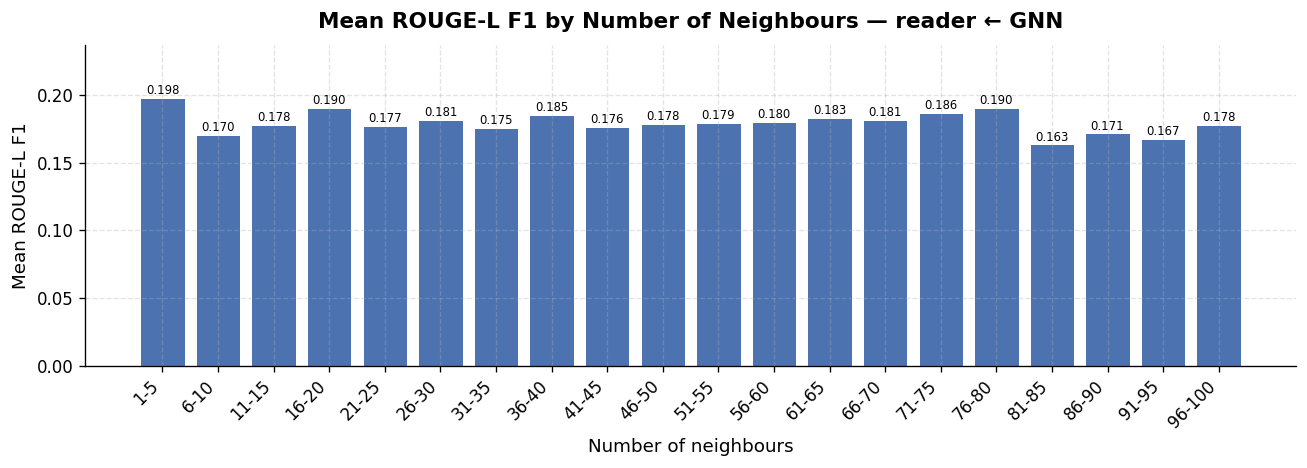

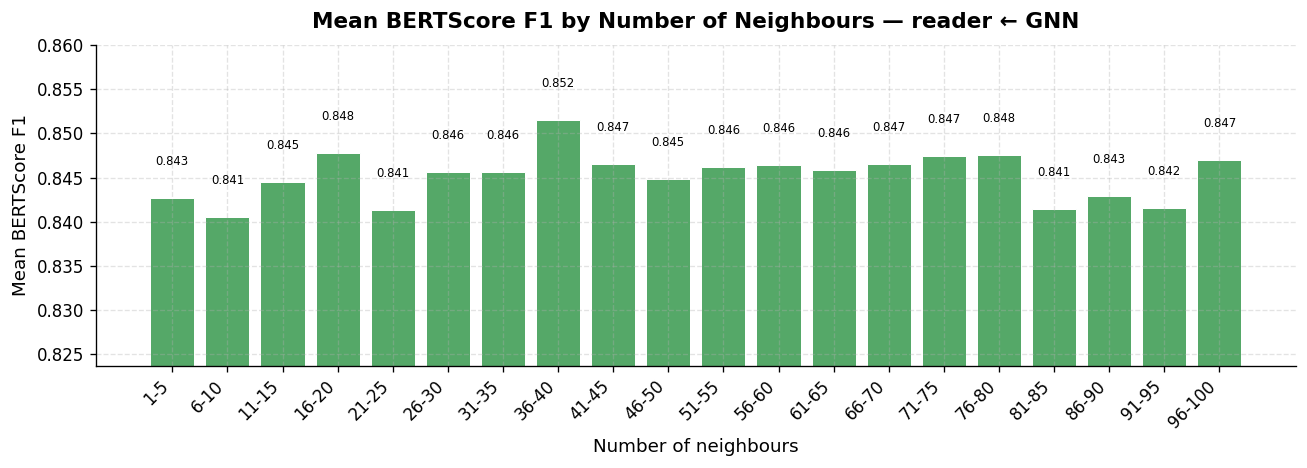

In [4]:
# ── ROUGE-L and BERTScore by neighbours ──────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean, title=f'Mean ROUGE-L F1 by Number of Neighbours — {ARM}',
         ylabel='Mean ROUGE-L F1', color='#4C72B0', ylim=(0, max(rougel_mean.dropna()) * 1.2))

bert_mean = weighted_group_mean(df, 'bertscore_f1')
bar_plot(bert_mean, title=f'Mean BERTScore F1 by Number of Neighbours — {ARM}',
         ylabel='Mean BERTScore F1', color='#55A868',
         ylim=(bert_mean.dropna().min() * 0.98, bert_mean.dropna().max() * 1.01))

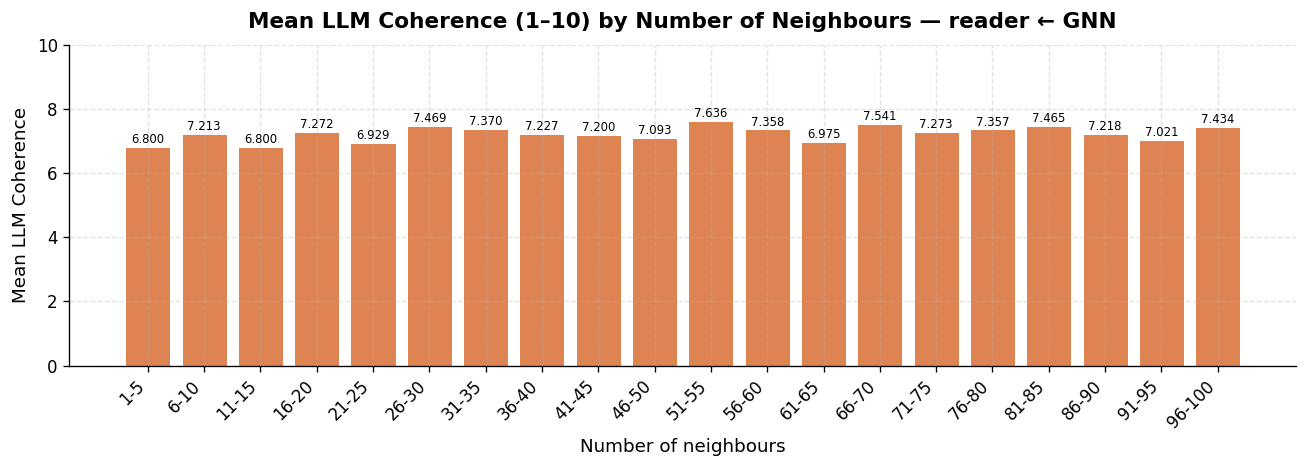

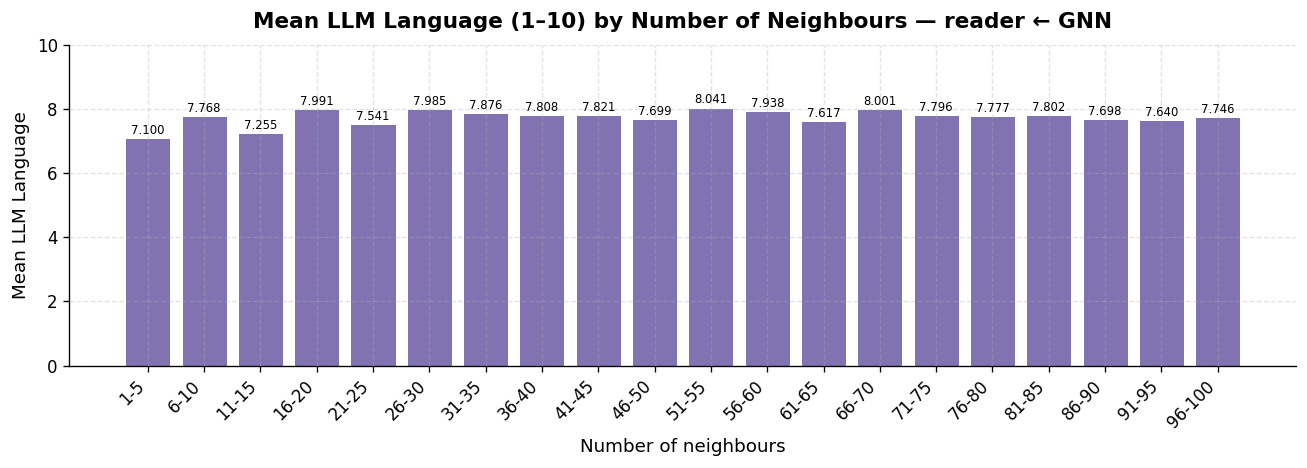

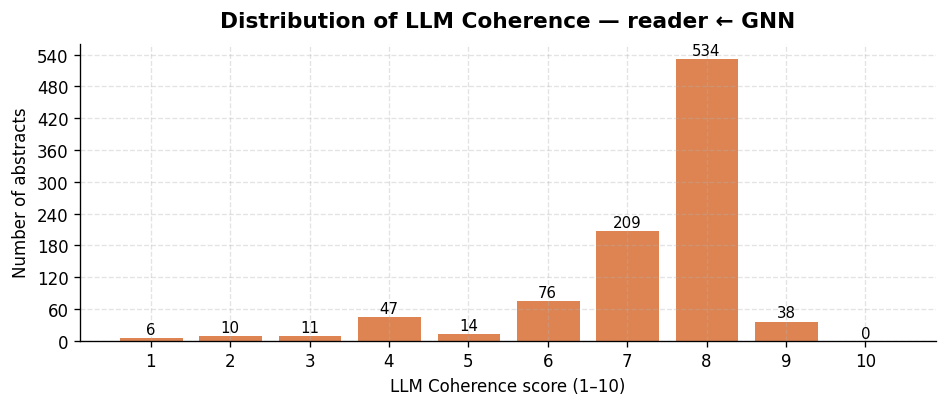

llm_coherence
1       6
2      10
3      11
4      47
5      14
6      76
7     209
8     534
9      38
10      0
Name: count, dtype: int64

In [5]:
# ── Coherence and language ───────────────────────────────────────────────────
bar_plot(weighted_group_mean(df, 'llm_coherence'),
         title=f'Mean LLM Coherence (1–10) by Number of Neighbours — {ARM}',
         ylabel='Mean LLM Coherence', color='#DD8452', ylim=(0, 10))
bar_plot(weighted_group_mean(df, 'llm_language'),
         title=f'Mean LLM Language (1–10) by Number of Neighbours — {ARM}',
         ylabel='Mean LLM Language', color='#8172B2', ylim=(0, 10))
dist_plot('llm_coherence', list(range(1, 11)), f'Distribution of LLM Coherence — {ARM}',
          'LLM Coherence score (1–10)', '#DD8452')

## A. Blind facets

Each abstract is labelled on its own from fixed lists; the score is whether the generated
label matches the gold label. Field is expected near the ceiling for every arm.

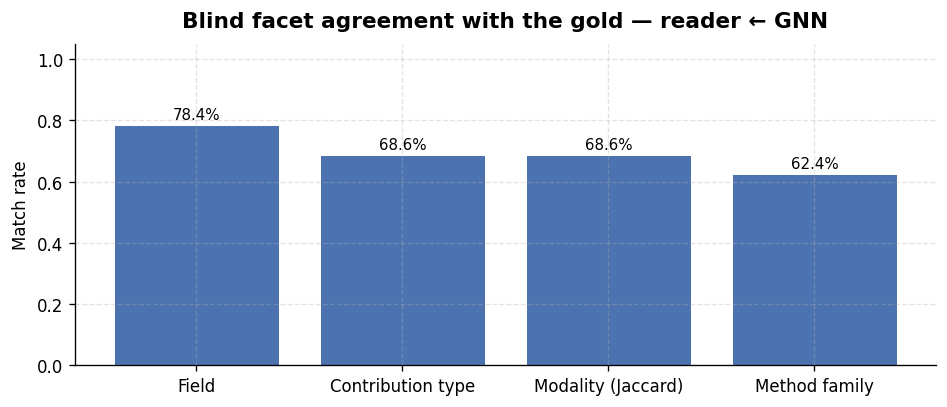

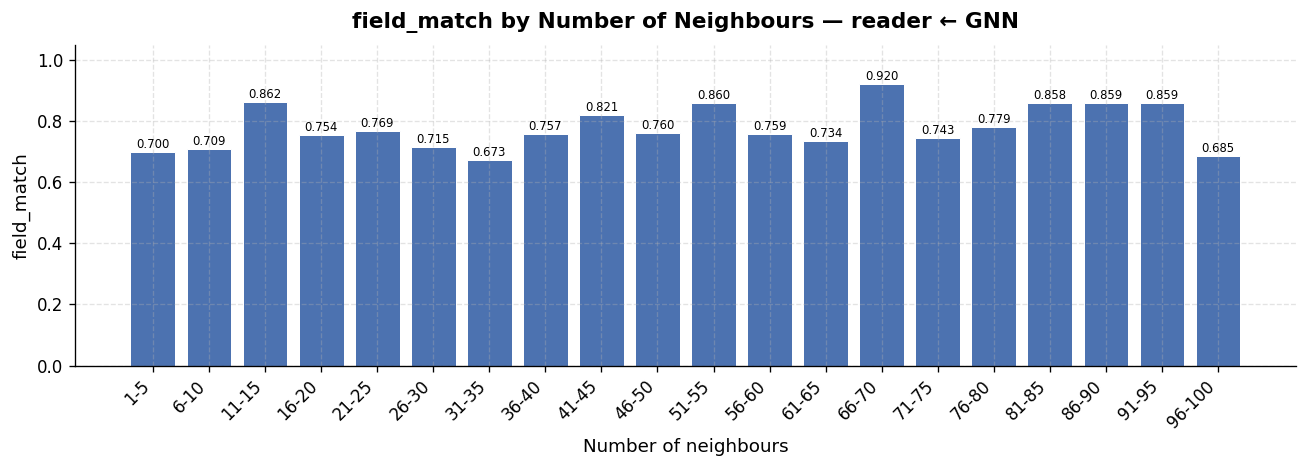

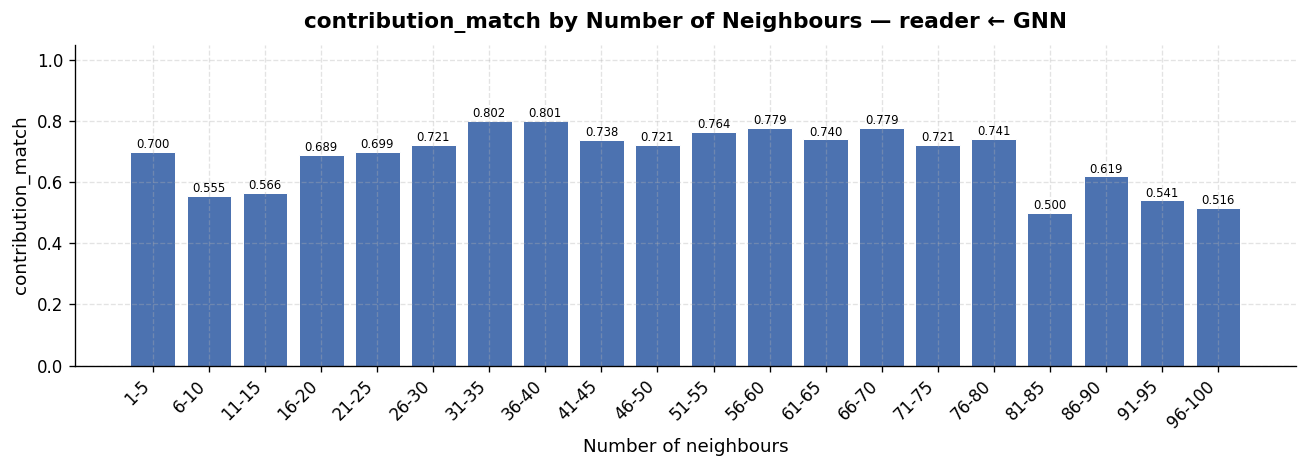

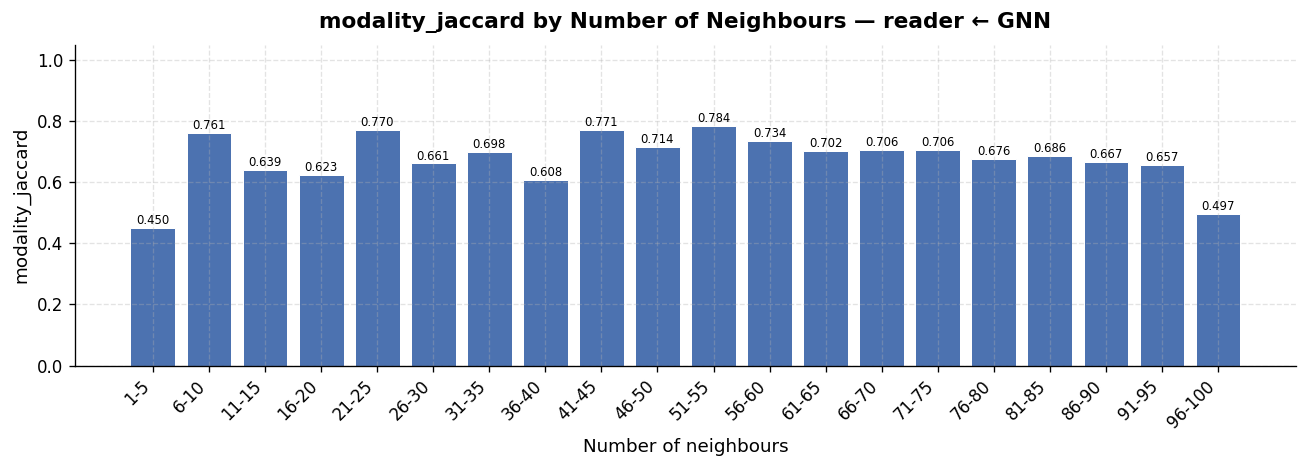

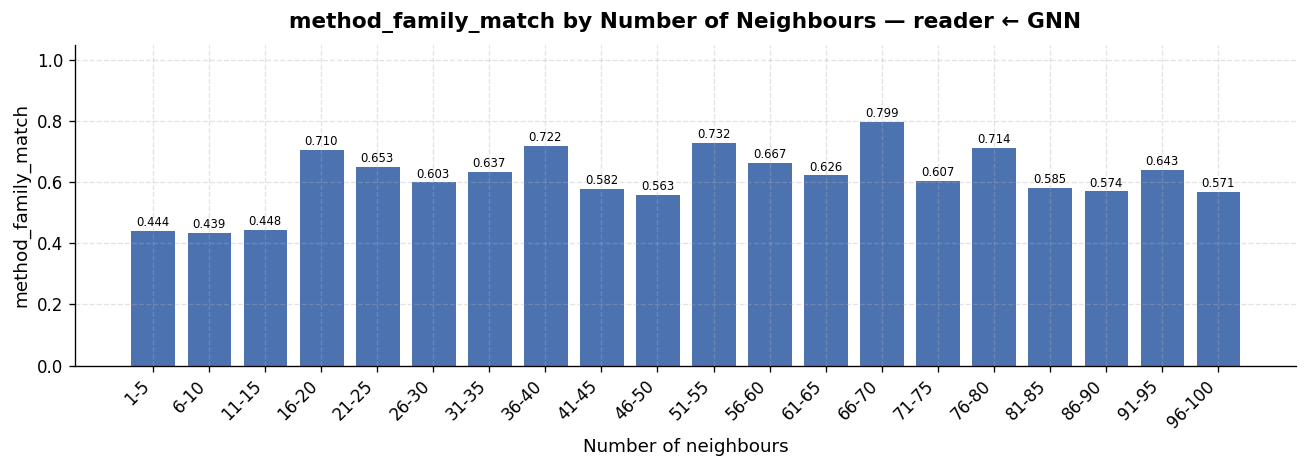

In [6]:
FACETS = ['field_match', 'contribution_match', 'modality_jaccard', 'method_family_match']
FACET_LABELS = ['Field', 'Contribution type', 'Modality (Jaccard)', 'Method family']
rates = df[FACETS].mean().values

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(FACET_LABELS, rates, color='#4C72B0', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f'{v:.1%}', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Match rate')
ax.set_title(f'Blind facet agreement with the gold — {ARM}', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()

for col in FACETS:
    bar_plot(weighted_group_mean(df, col), title=f'{col} by Number of Neighbours — {ARM}',
             ylabel=col, color='#4C72B0', ylim=(0, 1.05))

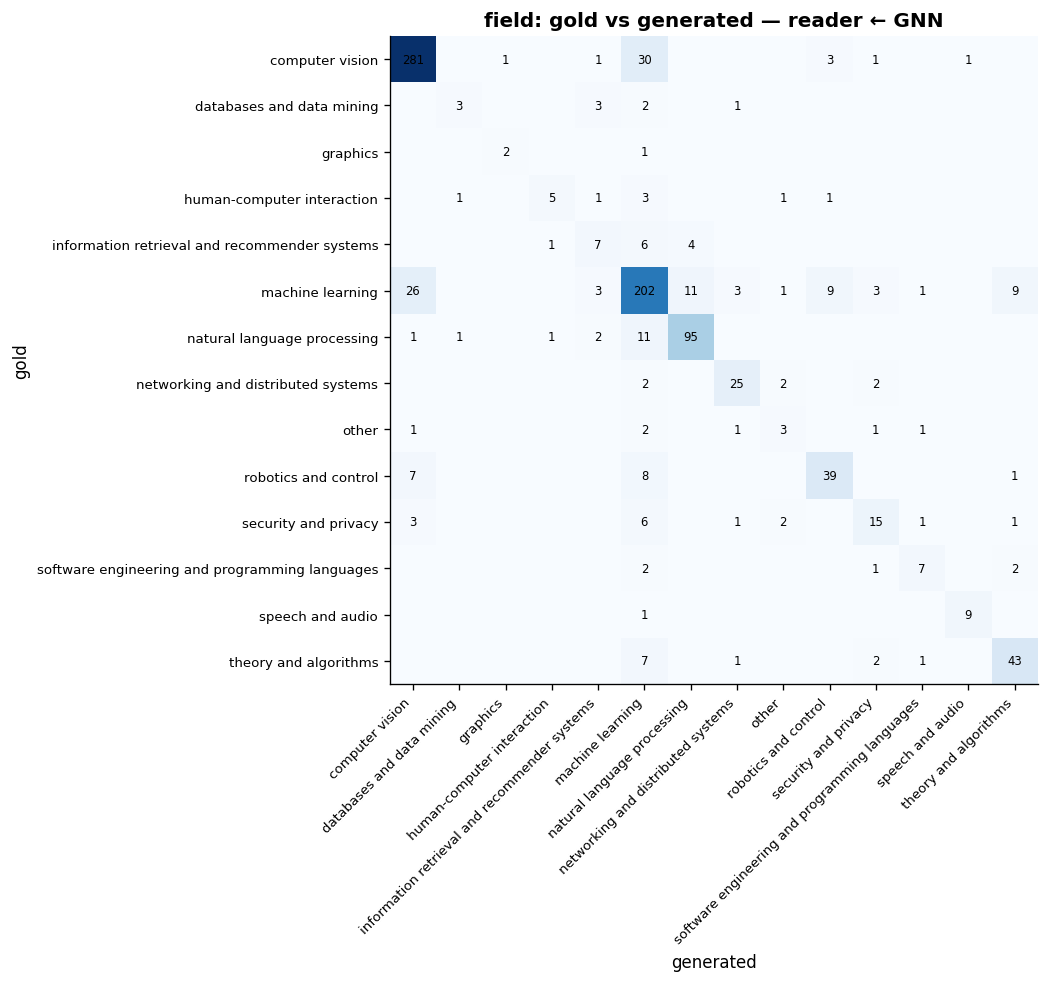

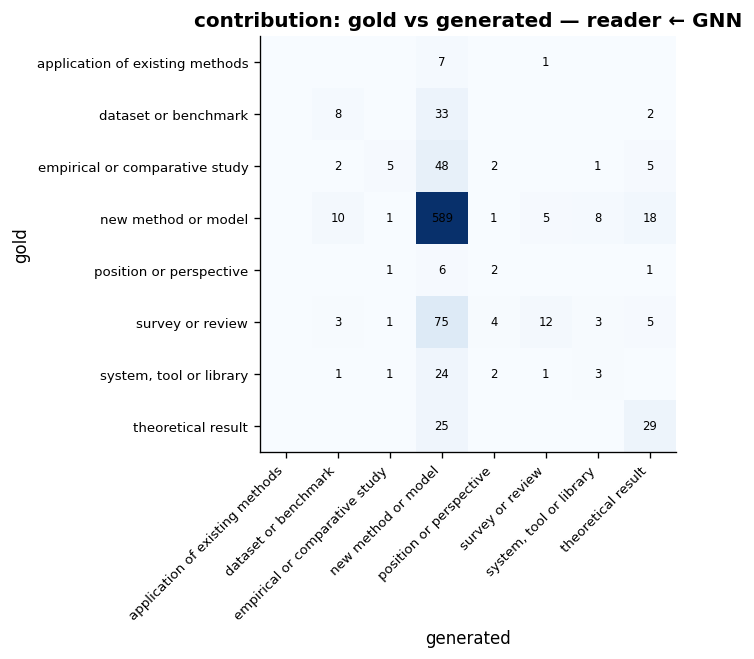

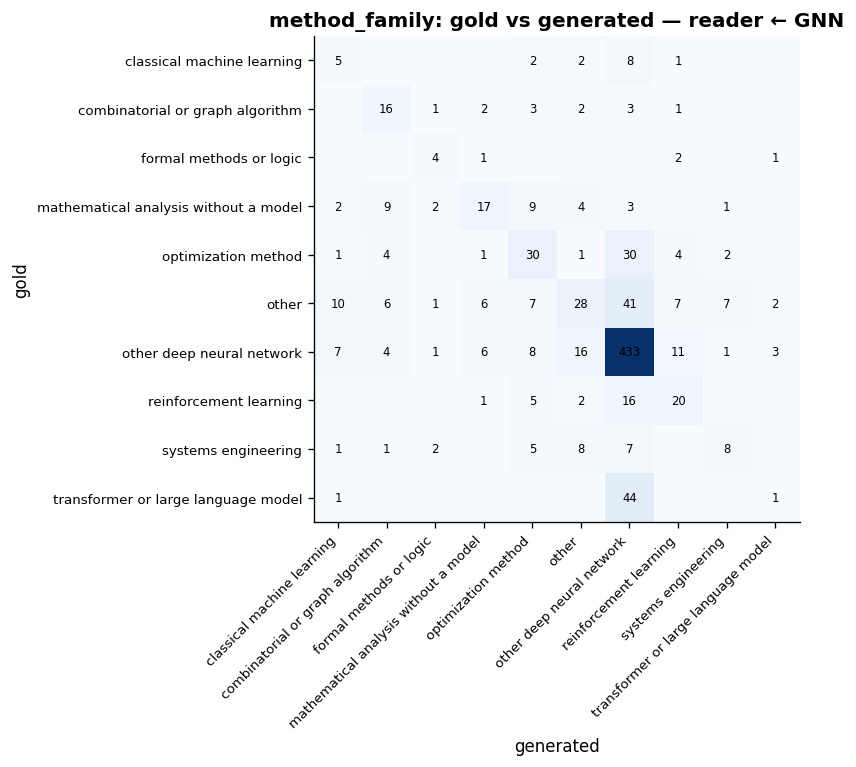

In [7]:
# ── Confusion tables: gold label (rows) vs generated label (columns) ─────────
def confusion(facet: str):
    table = pd.crosstab(df[f'gold_{facet}'], df[f'gen_{facet}'])
    labels = sorted(set(table.index) | set(table.columns))
    table = table.reindex(index=labels, columns=labels, fill_value=0)
    fig, ax = plt.subplots(figsize=(0.55 * len(labels) + 3, 0.45 * len(labels) + 2))
    ax.imshow(table.values, cmap='Blues')
    ax.grid(False)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if table.values[i, j]:
                ax.text(j, i, table.values[i, j], ha='center', va='center', fontsize=7)
    ax.set_xlabel('generated')
    ax.set_ylabel('gold')
    ax.set_title(f'{facet}: gold vs generated — {ARM}', fontsize=12, fontweight='bold')
    fig.tight_layout()
    plt.show()

for facet in ['field', 'contribution', 'method_family']:
    confusion(facet)

## B. Comparison with the gold

Subfield, problem and task on the anchored 0–3 scale (0 different, 1 related, 2 same with
differences in detail, 3 same).

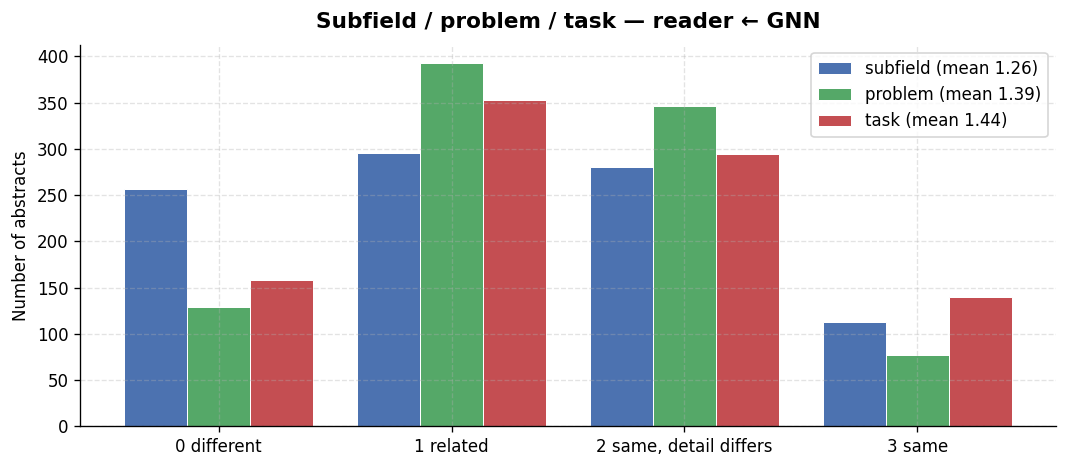

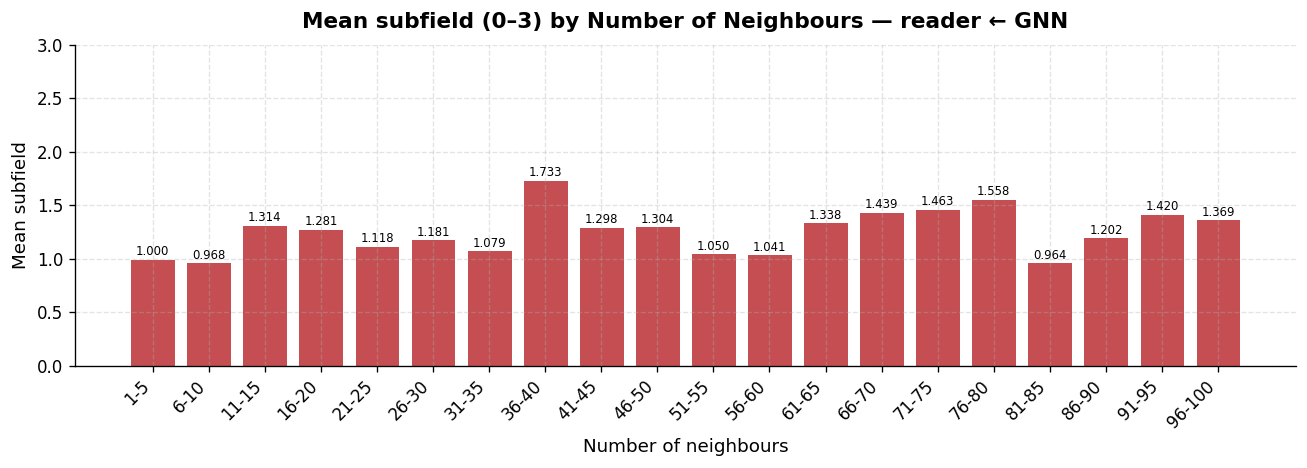

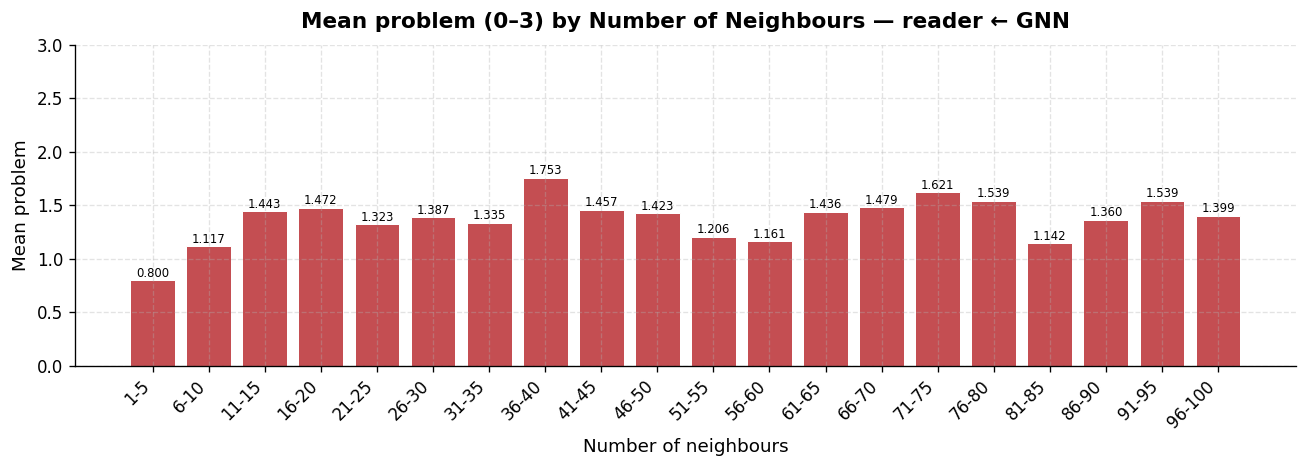

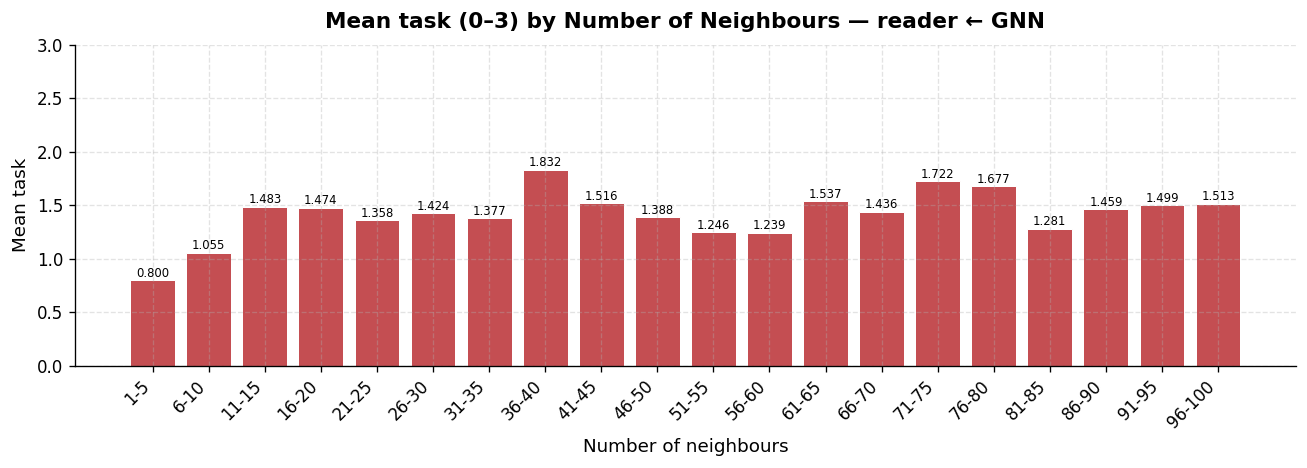

,subfield,problem,task
0,257,129,158
1,295,393,353
2,280,346,294
3,113,77,140


In [8]:
SCALE = ['subfield', 'problem', 'task']
counts = pd.DataFrame({c: df[c].dropna().round().astype(int).value_counts().reindex(range(4), fill_value=0)
                       for c in SCALE})

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(4)
for k, (c, color) in enumerate(zip(SCALE, ['#4C72B0', '#55A868', '#C44E52'])):
    ax.bar(x + (k - 1) * 0.27, counts[c].values, width=0.27, label=f'{c} (mean {df[c].mean():.2f})',
           color=color, edgecolor='white', linewidth=0.6)
ax.set_xticks(x)
ax.set_xticklabels(['0 different', '1 related', '2 same, detail differs', '3 same'])
ax.set_ylabel('Number of abstracts')
ax.set_title(f'Subfield / problem / task — {ARM}', fontsize=13, fontweight='bold', pad=10)
ax.legend()
fig.tight_layout()
plt.show()

for c in SCALE:
    bar_plot(weighted_group_mean(df, c), title=f'Mean {c} (0–3) by Number of Neighbours — {ARM}',
             ylabel=f'Mean {c}', color='#C44E52', ylim=(0, 3))
counts

claims per abstract:        5.59
supported per abstract:     0.80
contradicted per abstract:  2.25
claim precision (mean):     0.140
pooled precision:           0.143
abstracts with ≥1 contradiction: 71.0%
abstracts with no claims:   0.5%


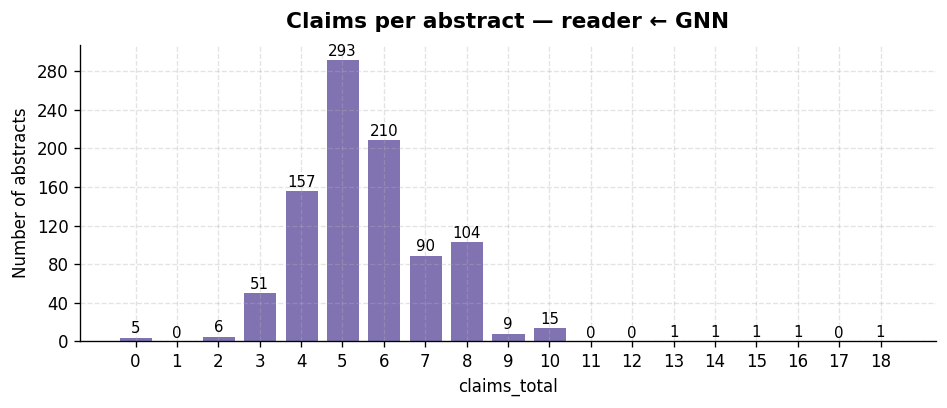

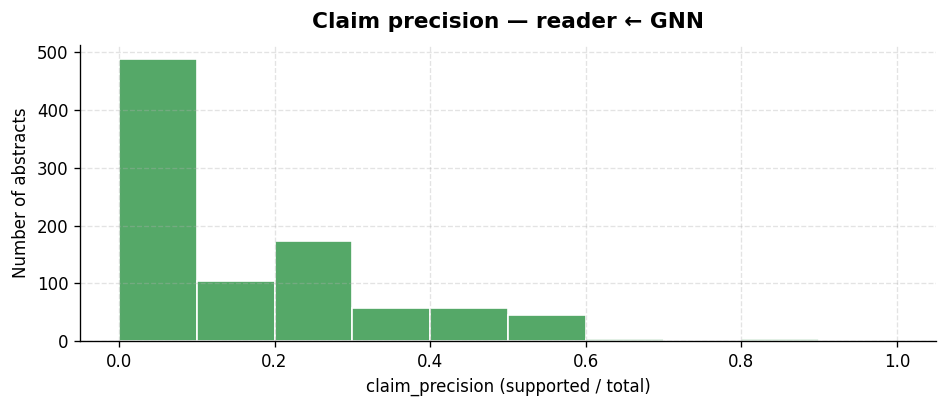

In [9]:
# ── Claims: specificity, precision, contradictions ───────────────────────────
print(f"claims per abstract:        {df['claims_total'].mean():.2f}")
print(f"supported per abstract:     {df['claims_supported'].mean():.2f}")
print(f"contradicted per abstract:  {df['claims_contradicted'].mean():.2f}")
print(f"claim precision (mean):     {df['claim_precision'].mean():.3f}")
print(f"pooled precision:           {df['claims_supported'].sum() / df['claims_total'].sum():.3f}")
print(f"abstracts with ≥1 contradiction: {(df['claims_contradicted'] > 0).mean():.1%}")
print(f"abstracts with no claims:   {(df['claims_total'] == 0).mean():.1%}")

max_claims = int(df['claims_total'].max())
dist_plot('claims_total', list(range(0, max_claims + 1)), f'Claims per abstract — {ARM}',
          'claims_total', '#8172B2')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df['claim_precision'].dropna(), bins=np.linspace(0, 1, 11), color='#55A868', edgecolor='white')
ax.set_xlabel('claim_precision (supported / total)')
ax.set_ylabel('Number of abstracts')
ax.set_title(f'Claim precision — {ARM}', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()

## C. Identification among hard distractors

The judge ranks the gold and its four nearest papers (never its own references). Chance is
20% correct and a mean rank of 3.

id correct (top-1): 25.4%   (chance 20%)
mean id rank:       2.67   (chance 3.00)
id MRR:             0.511   (chance 0.457)


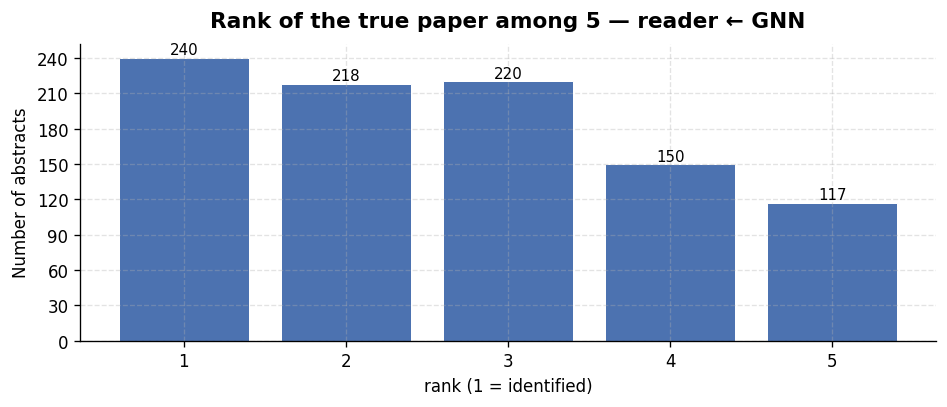

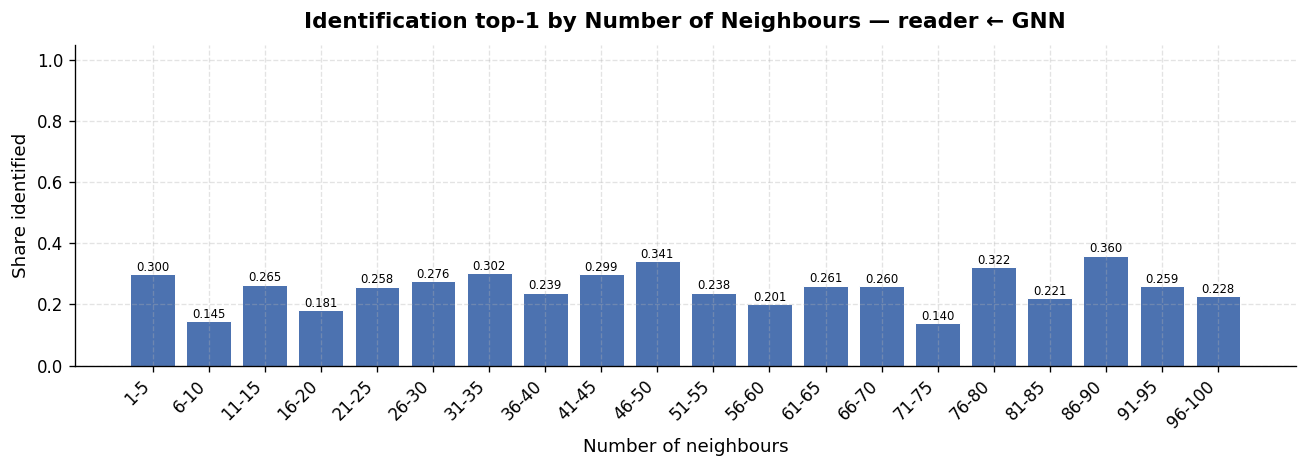

In [10]:
print(f"id correct (top-1): {df['id_correct'].mean():.1%}   (chance 20%)")
print(f"mean id rank:       {df['id_rank'].mean():.2f}   (chance 3.00)")
print(f"id MRR:             {(1 / df['id_rank']).mean():.3f}   (chance 0.457)")

counts = dist_plot('id_rank', [1, 2, 3, 4, 5], f'Rank of the true paper among 5 — {ARM}',
                   'rank (1 = identified)', '#4C72B0')
bar_plot(weighted_group_mean(df, 'id_correct'),
         title=f'Identification top-1 by Number of Neighbours — {ARM}',
         ylabel='Share identified', color='#4C72B0', ylim=(0, 1.05))

## No judge: TF-IDF identifiability and on-target margin

TF-IDF top-1 (among all 945 golds): 18.5%
TF-IDF MRR:                         0.305
on-target margin (mean):            -0.126
closer to a reference than to gold: 94.6%


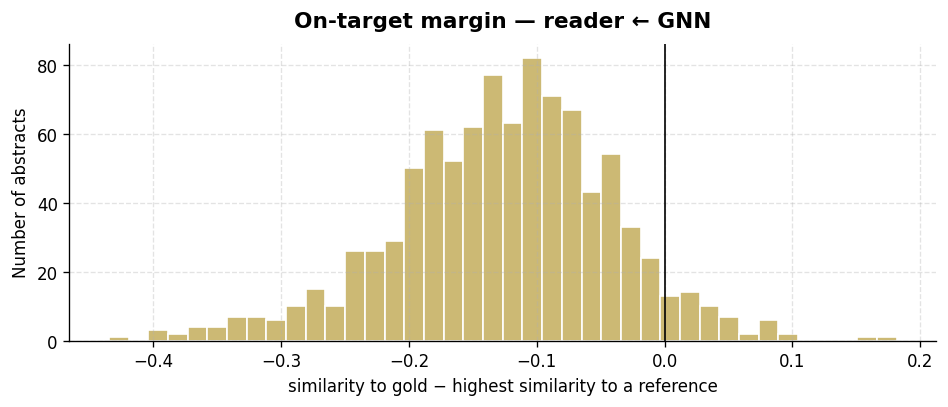

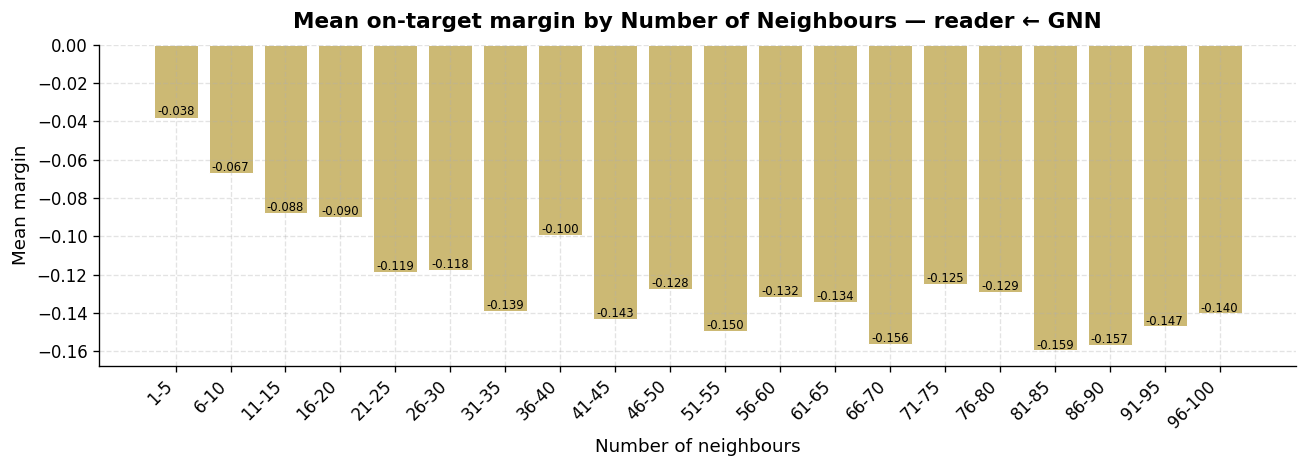

In [11]:
print(f"TF-IDF top-1 (among all {len(df)} golds): {df['tfidf_top1'].mean():.1%}")
print(f"TF-IDF MRR:                         {(1 / df['tfidf_rank']).mean():.3f}")
print(f"on-target margin (mean):            {df['ontarget_margin'].mean():.3f}")
print(f"closer to a reference than to gold: {(df['ontarget_margin'] < 0).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df['ontarget_margin'].dropna(), bins=40, color='#CCB974', edgecolor='white')
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('similarity to gold − highest similarity to a reference')
ax.set_ylabel('Number of abstracts')
ax.set_title(f'On-target margin — {ARM}', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()

bar_plot(weighted_group_mean(df, 'ontarget_margin'),
         title=f'Mean on-target margin by Number of Neighbours — {ARM}',
         ylabel='Mean margin', color='#CCB974')

## D. Pairwise preference

Only present when the CSV was scored with `--against`. 1 = this arm judged better in both
orders, 0.5 = split or tie, 0 = worse in both.

In [12]:
if 'pair_score' in df.columns:
    p = df['pair_score'].dropna()
    se = p.std() / np.sqrt(len(p))
    print(f"pair score: {p.mean():.3f} ± {se:.3f} (SE)   0.5 = no preference")
    print(f"wins both orders: {(p == 1).mean():.1%}   split/tie: {(p == 0.5).mean():.1%}   "
          f"loses both: {(p == 0).mean():.1%}")
    counts = p.value_counts().reindex([0.0, 0.25, 0.5, 0.75, 1.0], fill_value=0)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar([str(v) for v in counts.index], counts.values, color='#937860', edgecolor='white')
    ax.set_xlabel('pair_score')
    ax.set_ylabel('Number of abstracts')
    ax.set_title(f'Pairwise preference — {ARM}', fontsize=13, fontweight='bold', pad=10)
    fig.tight_layout()
    plt.show()
    bar_plot(weighted_group_mean(df, 'pair_score'),
             title=f'Pair score by Number of Neighbours — {ARM}',
             ylabel='Mean pair score', color='#937860', ylim=(0, 1.05))
else:
    print('no pair_score column: this CSV was scored without --against')

no pair_score column: this CSV was scored without --against


## Examples

In [13]:
pd.set_option('display.max_colwidth', 2000)
SHOW = ['node_id', 'original_abstract', 'generated_abstract']

# 2 examples per task score
(df[df['task'].notna()].sort_values('task').groupby('task', sort=True)
   .apply(lambda g: g.head(2)).reset_index(drop=True)[SHOW + ['subfield', 'problem', 'task']])

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_39929/3392447683.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2)).reset_index(drop=True)[SHOW + ['subfield', 'problem', 'task']])


,node_id,original_abstract,generated_abstract,subfield,problem,task
0,1089,"We deal with the \textit{selective classification} problem (supervised-learning problem with a rejection option), where we want to achieve the best performance at a certain level of coverage of the data. We transform the original $m$-class classification problem to $(m+1)$-class where the $(m+1)$-th class represents the model abstaining from making a prediction due to uncertainty. Inspired by portfolio theory, we propose a loss function for the selective classification problem based on the doubling rate of gambling. We show that minimizing this loss function has a natural interpretation as maximizing the return of a \textit{horse race}, where a player aims to balance between betting on an outcome (making a prediction) when confident and reserving one's winnings (abstaining) when not confident. This loss function allows us to train neural networks and characterize the uncertainty of prediction in an end-to-end fashion. In comparison with previous methods, our method requires almost no modification to the model inference algorithm or neural architecture. Experimentally, we show that our method can identify both uncertain and outlier data points, and achieves strong results on SVHN and CIFAR10 at various coverages of the data.","We propose a new method for training neural networks that is robust to label noise. Our method is based on the observation that the gradient of the loss function with respect to the network weights is a linear function of the label. We use this observation to derive a new loss function that is robust to label flips. We show that our method is effective in the presence of label noise, and that it is robust to the noise level. We also show that our method is robust to the noise type, and that it is effective in the presence both of symmetric and asymmetric noise.",0,0,0
1,55243,"We study a game between two firms in which each provide a service based on machine learning. The firms are presented with the opportunity to purchase a new corpus of data, which will allow them to potentially improve the quality of their products. The firms can decide whether or not they want to buy the data, as well as which learning model to build with that data. We demonstrate a reduction from this potentially complicated action space to a one-shot, two-action game in which each firm only decides whether or not to buy the data. The game admits several regimes which depend on the relative strength of the two firms at the outset and the price at which the data is being offered. We analyze the game's Nash equilibria in all parameter regimes and demonstrate that, in expectation, the outcome of the game is that the initially stronger firm's market position weakens whereas the initially weaker firm's market position becomes stronger. Finally, we consider the perspective of the users of the service and demonstrate that the expected outcome at equilibrium is not the one which maximizes the welfare of the consumers.",We study the problem of allocating a divisible good to a set of strategic agents. The agents are heterogeneous in their valuations and their valuations are private information. We consider a setting where the agents are not fully rational and their behavior is governed by a simple heuristic. We show that the resulting allocation is efficient and the seller can extract the entire surplus.,0,0,0
2,113755,"Recent studies have shown that deep neural networks (DNNs) are vulnerable to various attacks, including evasion attacks and poisoning attacks. On the defense side, there have been intensive interests in provable robustness against evasion attacks. In this paper, we focus on improving model robustness against more diverse threat models. Specifically, we provide the first unified framework using smoothing functional to certify the model robustness against general adversarial attacks. In particular, we propose the first robust training process RAB to cert

In [14]:
# Identified by TF-IDF but not by the judge, and the reverse
judge_only = df[(df['id_correct'] == 1) & (df['tfidf_rank'] > 1)]
tfidf_only = df[(df['id_correct'] == 0) & (df['tfidf_rank'] == 1)]
print(f'judge only: {len(judge_only)}   TF-IDF only: {len(tfidf_only)}')
tfidf_only.head(3)[SHOW + ['id_rank', 'id_options']]

judge only: 193   TF-IDF only: 128


,node_id,original_abstract,generated_abstract,id_rank,id_options
2,1121,"Various formal languages have been proposed in the literature for the individual-based modelling of ecological systems. These languages differ in their treatment of time and space. Each modelling language offers a distinct view and techniques for analyzing systems. Most of the languages are based on process calculi or P systems. In this article, we present a general overview of the existing modelling languages based on process calculi. We also discuss, briefly, other approaches such as P systems, cellular automata and Petri nets. Finally, we show advantages and disadvantages of these modelling languages and we propose some future research directions.","We present a new approach to the specification of complex systems, based on the combination of a process algebra with a spatial description language. The process algebra is used to describe the dynamic evolution of the system, while the spatial description language is used to describe the spatial organisation of the system. The two languages are combined in a way that allows the specification of complex systems in a natural and concise way. We illustrate the approach by means of a case study.",2,152273|184353|213866|202507
5,1171,"Fusion of 2D images and 3D point clouds is important because information from dense images can enhance sparse point clouds. However, fusion is challenging because 2D and 3D data live in different spaces. In this work, we propose MVPNet (Multi-View PointNet), where we aggregate 2D multi-view image features into 3D point clouds, and then use a point based network to fuse the features in 3D canonical space to predict 3D semantic labels. To this end, we introduce view selection along with a 2D-3D feature aggregation module. Extensive experiments show the benefit of leveraging features from dense images and reveal superior robustness to varying point cloud density compared to 3D-only methods. On the ScanNetV2 benchmark, our MVPNet significantly outperforms prior point cloud based approaches on the task of 3D Semantic Segmentation. It is much faster to train than the large networks of the sparse voxel approach. We provide solid ablation studies to ease the future design of 2D-3D fusion methods and their extension to other tasks, as we showcase for 3D instance segmentation.","We present a novel approach for 3D scene understanding that is able to process large-scale point clouds efficiently. Our approach is based on a multi-scale convolutional neural network (CNN) that is applied to a 3D voxel grid. The multi-scale CNN is able to learn features at different levels of detail, which are then used to predict semantic labels for each voxel. We show that our approach is able to achieve state-of-the-art performance on the Semantic3D benchmark dataset.",2,89399|7502|373117|167989
6,1228,"Detecting frequent items is a fundamental problem in data streaming research. However, in many applications, besides the frequent items themselves, meta data such as the timestamps of when the frequent items appeared or other application-specific data that ""arrives"" with the frequent items needs to be reported too. #R##N#To this end, we introduce the Neighborhood Detection problem in graph streams, which both accurately models situations such as those stated above, and addresses the fundamental problem of detecting large neighborhoods or stars in graph streams. In Neighborhood Detection, an algorithm receives the edges of a bipartite graph $G=(A, B, E)$ with $|A| = n$ and $|B| = \text{poly}~n$ in arbitrary order and is given a threshold parameter $d$. Provided that there is at least one $A$-node of degree at least $d$, the objective is to output a node $a \in A$ together with at least $\frac{d}{c}$ of its neighbors, where $c$ is the approximation factor. #R##N#We show that in insertion-only streams, there is a one-pass $\tilde{O}(n + n^{\frac{1}{c}}d)$ space $c$-approximation streaming algorithm, for integral 

In [15]:
# Most contradicted abstracts
df.sort_values('claims_contradicted', ascending=False).head(3)[
    SHOW + ['claims_total', 'claims_supported', 'claims_contradicted']]

,node_id,original_abstract,generated_abstract,claims_total,claims_supported,claims_contradicted
214,41033,"Egocentric vision (a.k.a. first-person vision - FPV) applications have thrived over the past few years, thanks to the availability of affordable wearable cameras and large annotated datasets. The position of the wearable camera (usually mounted on the head) allows recording exactly what the camera wearers have in front of them, in particular hands and manipulated objects. This intrinsic advantage enables the study of the hands from multiple perspectives: localizing hands and their parts within the images; understanding what actions and activities the hands are involved in; and developing human-computer interfaces that rely on hand gestures. In this survey, we review the literature that focuses on the hands using egocentric vision, categorizing the existing approaches into: localization (where are the hands or part of them?); interpretation (what are the hands doing?); and application (e.g., systems that used egocentric hand cues for solving a specific problem). Moreover, a list of the most prominent datasets with hand-based annotations is provided.","We present a novel approach to the problem of human action recognition in RGB-D videos. Our approach is based on the observation that the human body is a rigid object, and that the motion of the body is a combination of rigid and non-rigid motions. We propose to model the human body as a rigid object, and to use the rigid motion of the body to infer the non-rigid motion of the body parts. We propose to use a combination of a rigid motion model and a non-rigid motion model to infer the motion of the body parts from the motion of the body. We propose to use the rigid motion model to infer the non-rigidity of the body parts, and to use the non-rigidity to infer the motion of each body part. We propose to use an ensemble of rigid motion models to infer the non-rigion of the body parts, to infer the motion of body parts, and to infer the motion of individual body parts. We propose a novel approach to the human action recognition problem, which is based on the observation of the human body as a combination of rigid and flexible motions. We propose to use this observation to infer the motion of a body part from the motion of the whole body. We propose to infer the motion of an individual body part from the motion and the non-rigidity. We propose to use these observations to infer the motion of all body parts from the motion and the rigidity of the whole body.",10,0,10
225,43657,"We propose a planning and perception mechanism for a robot (agent), that can only observe the underlying environment partially, in order to solve an image classification problem. A three-layer architecture is suggested that consists of a meta-layer that decides the intermediate goals, an action-layer that selects local actions as the agent navigates towards a goal, and a classification-layer that evaluates the reward and makes a prediction. We design and implement these layers using deep reinforcement learning. A generalized policy gradient algorithm is utilized to learn the parameters of these layers to maximize the expected reward. Our proposed methodology is tested on the MNIST dataset of handwritten digits, which provides us with a level of explainability while interpreting the agent's intermediate goals and course of action.","In this paper, we propose a novel approach to collaborative decision making in multi-robot systems. Our approach is based on the idea of using a deep neural network to learn a collaborative decision making policy. The policy is learned by training the network on a large set of simulated scenarios. The network is trained to predict the best action for a given scenario. The network is trained using a reinforcement learning algorithm. The network is trained on a large set of scenarios that are generated by a simulator. The network is trained in a supervised manner. The network is tra

## Paired comparison with another arm

Set `OTHER` to another arm's `evaluated_result_detailed.csv`. Differences are this arm minus
the other, per paper on the shared papers; SE = sd / √n. Positive means this arm is higher, which
is better for every metric except `claims_contradicted`, `id_rank` and `tfidf_rank`.

In [16]:
OTHER = '../2026-10-09-14541449_run11-reader-refs-mean/evaluated_result_detailed.csv'
OTHER_NAME = 'reader ← refs-mean'

if os.path.exists(OTHER):
    other = pd.read_csv(OTHER)
    COMPARE = [c for c in NUMERIC + ['tfidf_top1'] if c != 'pair_score']
    for col in COMPARE:
        if col in other.columns:
            other[col] = pd.to_numeric(other[col], errors='coerce')
    other['tfidf_top1'] = (other['tfidf_rank'] == 1).astype(float)
    both = df.merge(other, on='node_id', suffixes=('', '_other'))
    rows = []
    for col in COMPARE:
        d = (both[col] - both[f'{col}_other']).dropna()
        rows.append({'metric': col, ARM: both[col].mean(), OTHER_NAME: both[f'{col}_other'].mean(),
                     'diff': d.mean(), 'SE': d.std() / np.sqrt(len(d)), 'n': len(d)})
    paired = pd.DataFrame(rows).set_index('metric')
    paired['z'] = paired['diff'] / paired['SE']
    display(paired.round(3))

    # Relative difference on the main per-dimension metrics
    MAIN = ['field_match', 'contribution_match', 'modality_jaccard', 'method_family_match',
            'subfield', 'problem', 'task', 'claim_precision', 'id_correct', 'tfidf_top1']
    rel = paired.loc[MAIN, 'diff'] / paired.loc[MAIN, OTHER_NAME]
    err = paired.loc[MAIN, 'SE'] / paired.loc[MAIN, OTHER_NAME]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(MAIN, rel.values, yerr=1.96 * err.values, capsize=3,
           color=['#55A868' if v > 0 else '#C44E52' for v in rel.values], edgecolor='white')
    ax.axhline(0, color='black', linewidth=1)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_ylabel(f'relative difference vs {OTHER_NAME}')
    ax.set_title(f'{ARM} vs {OTHER_NAME} (95% CI)', fontsize=13, fontweight='bold', pad=10)
    plt.xticks(rotation=30, ha='right')
    fig.tight_layout()
    plt.show()
else:
    print(f'{OTHER} not found yet')

../2026-10-09-14541449_run11-reader-refs-mean/evaluated_result_detailed.csv not found yet
